In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
import os

In [27]:
GAMES_PATH = os.environ.get('GAMES_DATA_PATH', '/content/drive/MyDrive/ML Projects/Game-recommendation-system/github-repo/data/raw/games.csv')
RECOMMENDATIONS_PATH = os.environ.get('RECOMMENDATIONS_DATA_PATH', '/content/drive/MyDrive/ML Projects/Game-recommendation-system/github-repo/data/raw/recommendations.csv')
USERS_PATH = os.environ.get('USERS_DATA_PATH', '/content/drive/MyDrive/ML Projects/Game-recommendation-system/github-repo/data/raw/users.csv')

# Load games fully (small dataset)
games = pd.read_csv(GAMES_PATH)

# Stratified chunked sampling for recommendations
sample_fraction = 0.0125  # ~1.25% sample yields roughly 500k rows safely
chunks = []

for chunk in pd.read_csv(RECOMMENDATIONS_PATH, chunksize=500000):
    # Group by app_id, sample proportionally, and explicitly restore the grouping key 'app_id'
    sampled_chunk = chunk.groupby('app_id', group_keys=False).apply(
        lambda x: x.sample(n=max(1, int(len(x) * sample_fraction)), random_state=42) if len(x) > 0 else x,
        include_groups=True
    )
    chunks.append(sampled_chunk)

recommendations = pd.concat(chunks, axis=0).reset_index(drop=True)
print(f"Sampled recommendations down to: {recommendations.shape}")

# Stream and filter users based on the sampled users in recommendations
sampled_user_ids = set(recommendations['user_id'].unique())
user_chunks = []

for chunk in pd.read_csv(USERS_PATH, chunksize=500000):
    filtered_chunk = chunk[chunk['user_id'].isin(sampled_user_ids)]
    user_chunks.append(filtered_chunk)

users = pd.concat(user_chunks, axis=0).reset_index(drop=True)
print(f"Sampled users down to: {users.shape}")

/tmp/ipykernel_561/2345224178.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_chunk = chunk.groupby('app_id', group_keys=False).apply(
/tmp/ipykernel_561/2345224178.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_chunk = chunk.groupby('app_id', group_keys=False).apply(
/tmp/ipykernel_561/2345224178.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. 

Sampled recommendations down to: (643995, 8)
Sampled users down to: (475229, 3)


## 1. Structural Overview: Shape & Data Types

In [28]:
print(f"Games shape: {games.shape}")
print(f"Recommendations shape: {recommendations.shape}")
print(f"Users shape: {users.shape}")

print("\n--- Games Columns & Types ---")
games.info()

print("\n--- Recommendations Columns & Types ---")
recommendations.info()

print("\n--- Users Columns & Types ---")
users.info()

Games shape: (50872, 13)
Recommendations shape: (643995, 8)
Users shape: (475229, 3)

--- Games Columns & Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50872 entries, 0 to 50871
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   app_id          50872 non-null  int64  
 1   title           50872 non-null  object 
 2   date_release    50872 non-null  object 
 3   win             50872 non-null  bool   
 4   mac             50872 non-null  bool   
 5   linux           50872 non-null  bool   
 6   rating          50872 non-null  object 
 7   positive_ratio  50872 non-null  int64  
 8   user_reviews    50872 non-null  int64  
 9   price_final     50872 non-null  float64
 10  price_original  50872 non-null  float64
 11  discount        50872 non-null  float64
 12  steam_deck      50872 non-null  bool   
dtypes: bool(4), float64(3), int64(3), object(3)
memory usage: 3.7+ MB

--- Recommendations Columns 

In [34]:
games.sample(5)

,app_id,title,date_release,win,mac,linux,rating,positive_ratio,user_reviews,price_final,price_original,discount,steam_deck
29203,1233200,Wanko of Marriage ~Welcome to The Dog's Tail!~,2020-10-20,True,False,False,Mixed,60,10,9.99,9.99,0.0,True
43916,1692430,Larry The Unlucky Part 1,2021-08-09,True,False,False,Very Positive,94,138,0.00,0.00,0.0,True
33198,827940,Marvellous Inc.,2018-04-27,True,True,True,Positive,87,16,11.99,11.99,0.0,True
32296,443250,Legacy of the Elder Star,2016-06-07,True,True,True,Very Positive,88,53,0.00,0.00,0.0,True
42770,2306390,Soul Knight: The Forest of Spirits,2023-02-16,True,False,False,Positive,100,12,1.99,1.99,0.0,True


In [35]:
recommendations.sample(5)

,app_id,helpful,funny,date,is_recommended,hours,user_id,review_id
483060,242760,2,0,2022-08-21,True,26.1,4002164,33682526
115753,680420,0,0,2021-04-02,False,0.6,14102671,9429412
503375,206420,0,0,2015-12-19,True,8.4,7129790,35077753
64552,377160,0,0,2020-12-02,True,102.2,10847340,5419719
91943,1172380,0,0,2020-07-03,True,15.9,8159643,7144218


In [36]:
users.sample(5)

,user_id,products,reviews
150474,5227436,17.0,3.0
358520,11573997,196.0,1.0
281744,13666570,72.0,9.0
456065,11819116,143.0,1.0
473493,8787696,124.0,6.0


## 2. Completeness: Checking Missing Values

In [29]:
print("Missing Values in Games:")
display(games.isnull().sum())

print("\nMissing Values in Recommendations:")
display(recommendations.isnull().sum())

print("\nMissing Values in Users:")
display(users.isnull().sum())

Missing Values in Games:


,0
app_id,0
title,0
date_release,0
win,0
mac,0
linux,0
rating,0
positive_ratio,0
user_reviews,0
price_final,0



Missing Values in Recommendations:


,0
app_id,0
helpful,0
funny,0
date,0
is_recommended,0
hours,0
user_id,0
review_id,0



Missing Values in Users:


,0
user_id,0
products,0
reviews,0


## 3. Uniqueness: Checking Duplicate Entries

In [30]:
print(f"Duplicate rows in Games: {games.duplicated().sum()}")
print(f"Duplicate rows in Recommendations: {recommendations.duplicated().sum()}")
print(f"Duplicate rows in Users: {users.duplicated().sum()}")

Duplicate rows in Games: 0
Duplicate rows in Recommendations: 0
Duplicate rows in Users: 0


## 4. Visualizations & Distributions

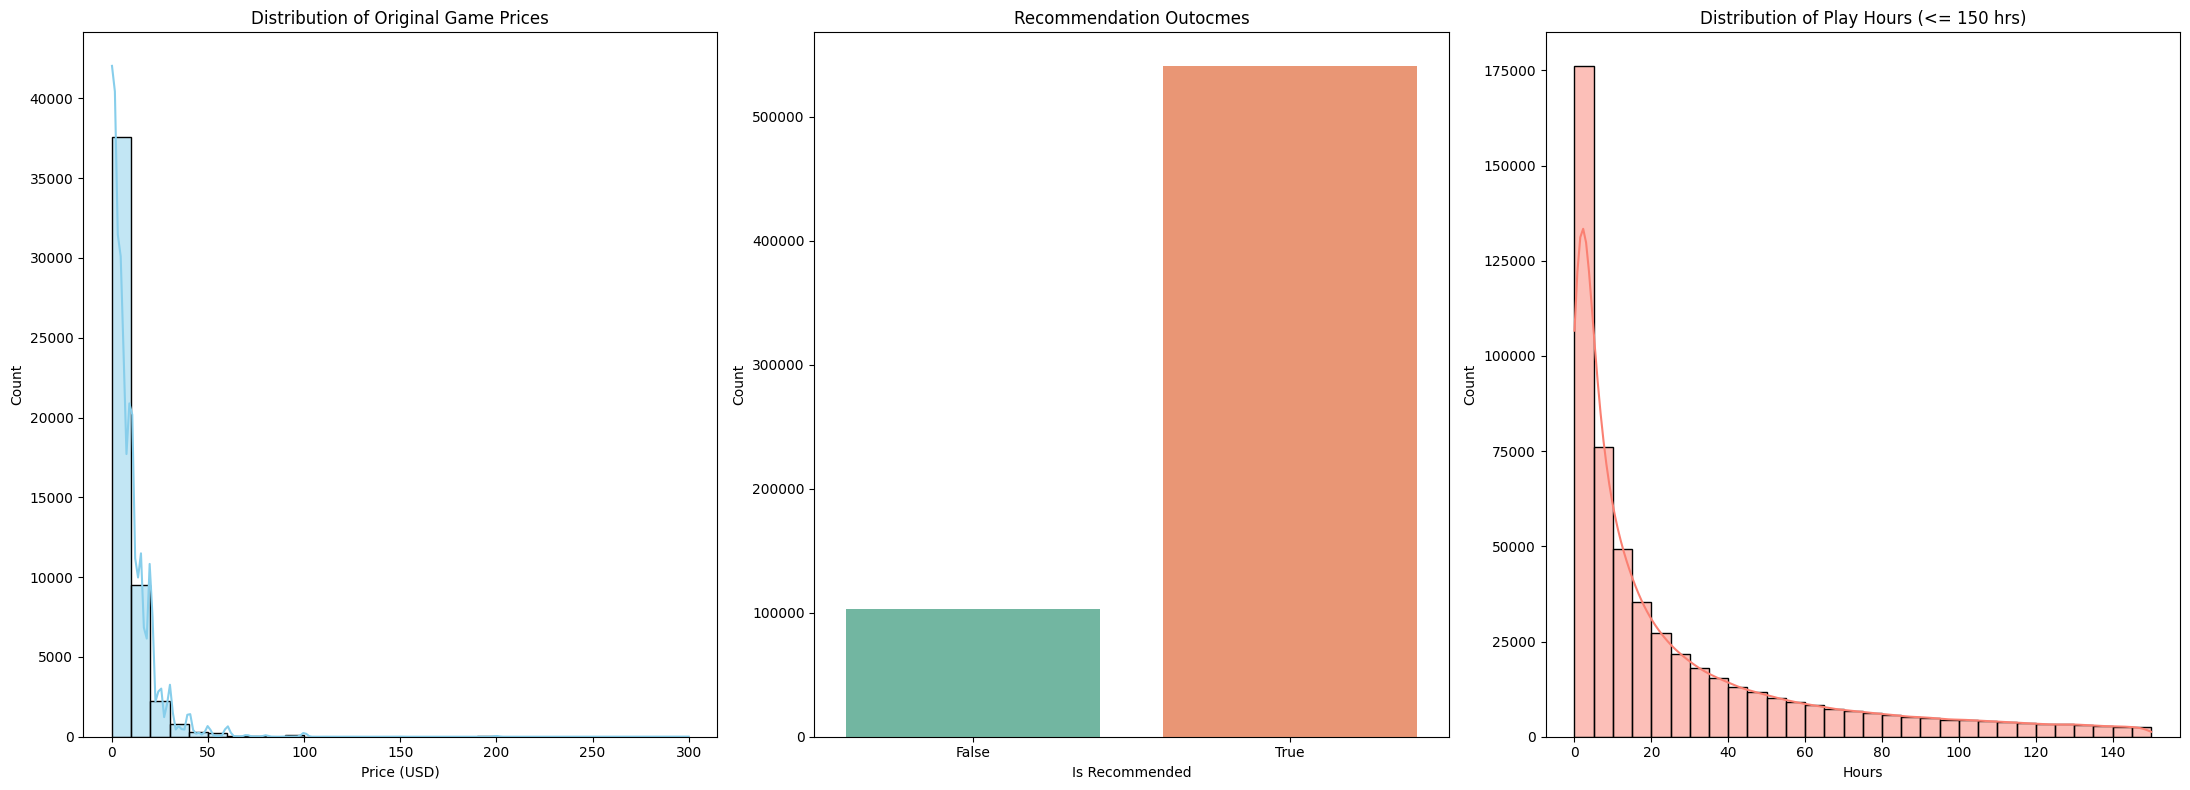

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(22, 8))

# 1. Distribution of Game Prices (Original Price)
sns.histplot(ax=axes[0], data=games, x='price_original', bins=30, kde=True, color='skyblue')
axes[0].set_title('Distribution of Original Game Prices')
axes[0].set_xlabel('Price (USD)')
axes[0].set_ylabel('Count')

# 2. Ratio of Recommended vs Not Recommended games
sns.countplot(ax=axes[1], data=recommendations, x='is_recommended', palette='Set2', hue='is_recommended', legend=False)
axes[1].set_title('Recommendation Outocmes')
axes[1].set_xlabel('Is Recommended')
axes[1].set_ylabel('Count')

# 3. Distribution of Hours Played in Sampled Reviews (Filtered outliers > 150 hours for visualization)
sns.histplot(ax=axes[2], data=recommendations[recommendations['hours'] <= 150], x='hours', bins=30, kde=True, color='salmon')
axes[2].set_title('Distribution of Play Hours (<= 150 hrs)')
axes[2].set_xlabel('Hours')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

## 5. Relationships & Key Metrics

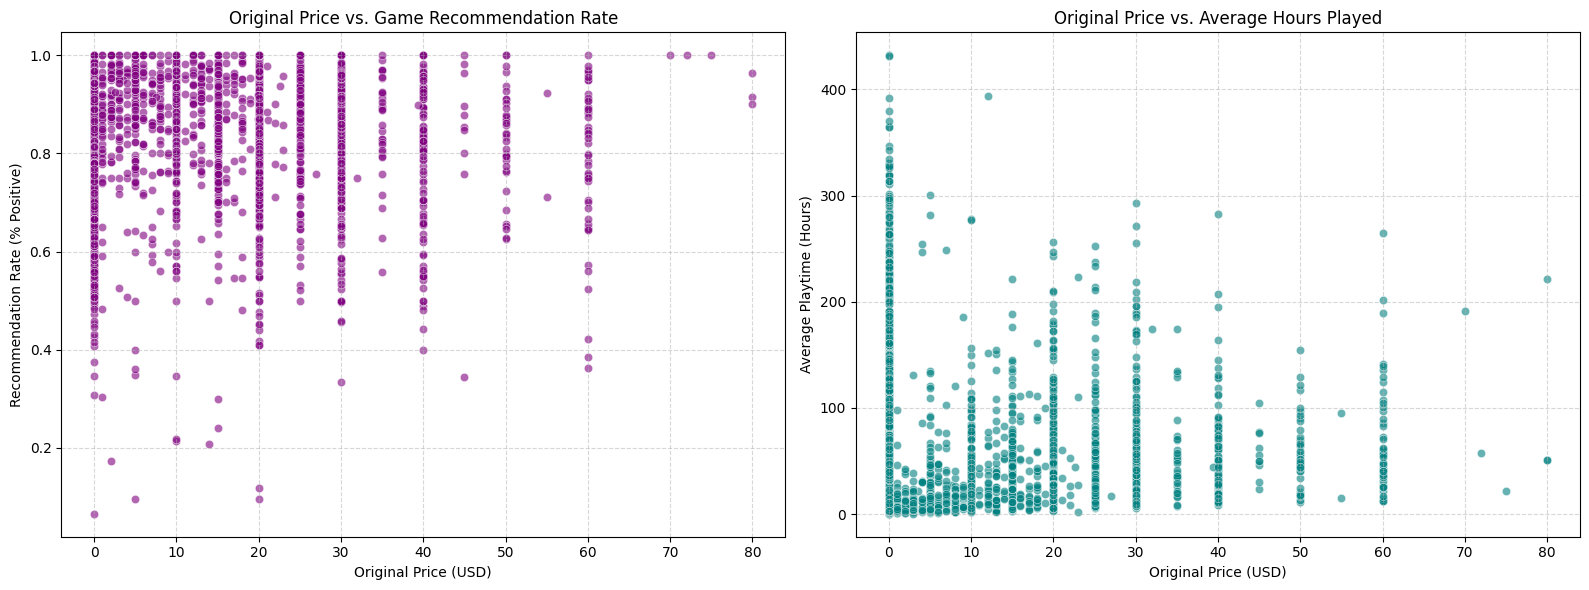

In [32]:
# Join games with recommendation metrics to explore price vs. recommendation behavior

# Calculate recommendation rate and average play hours per game
game_stats = recommendations.groupby('app_id').agg(
    recommend_rate=('is_recommended', 'mean'),
    avg_hours=('hours', 'mean'),
    review_count=('review_id', 'count')
).reset_index()

merged_df = pd.merge(games, game_stats, on='app_id')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Relationship between Game Price and Recommendation Rate (for games with >= 20 reviews to ensure stability)
sns.scatterplot(ax=axes[0], data=merged_df[merged_df['review_count'] >= 20], x='price_original', y='recommend_rate', alpha=0.6, color='purple')
axes[0].set_title('Original Price vs. Game Recommendation Rate')
axes[0].set_xlabel('Original Price (USD)')
axes[0].set_ylabel('Recommendation Rate (% Positive)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Relationship between Game Price and Average Hours Played
sns.scatterplot(ax=axes[1], data=merged_df[merged_df['review_count'] >= 20], x='price_original', y='avg_hours', alpha=0.6, color='teal')
axes[1].set_title('Original Price vs. Average Hours Played')
axes[1].set_xlabel('Original Price (USD)')
axes[1].set_ylabel('Average Playtime (Hours)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 5 (Improved): Analyzing Pricing Relationships with Advanced Visuals


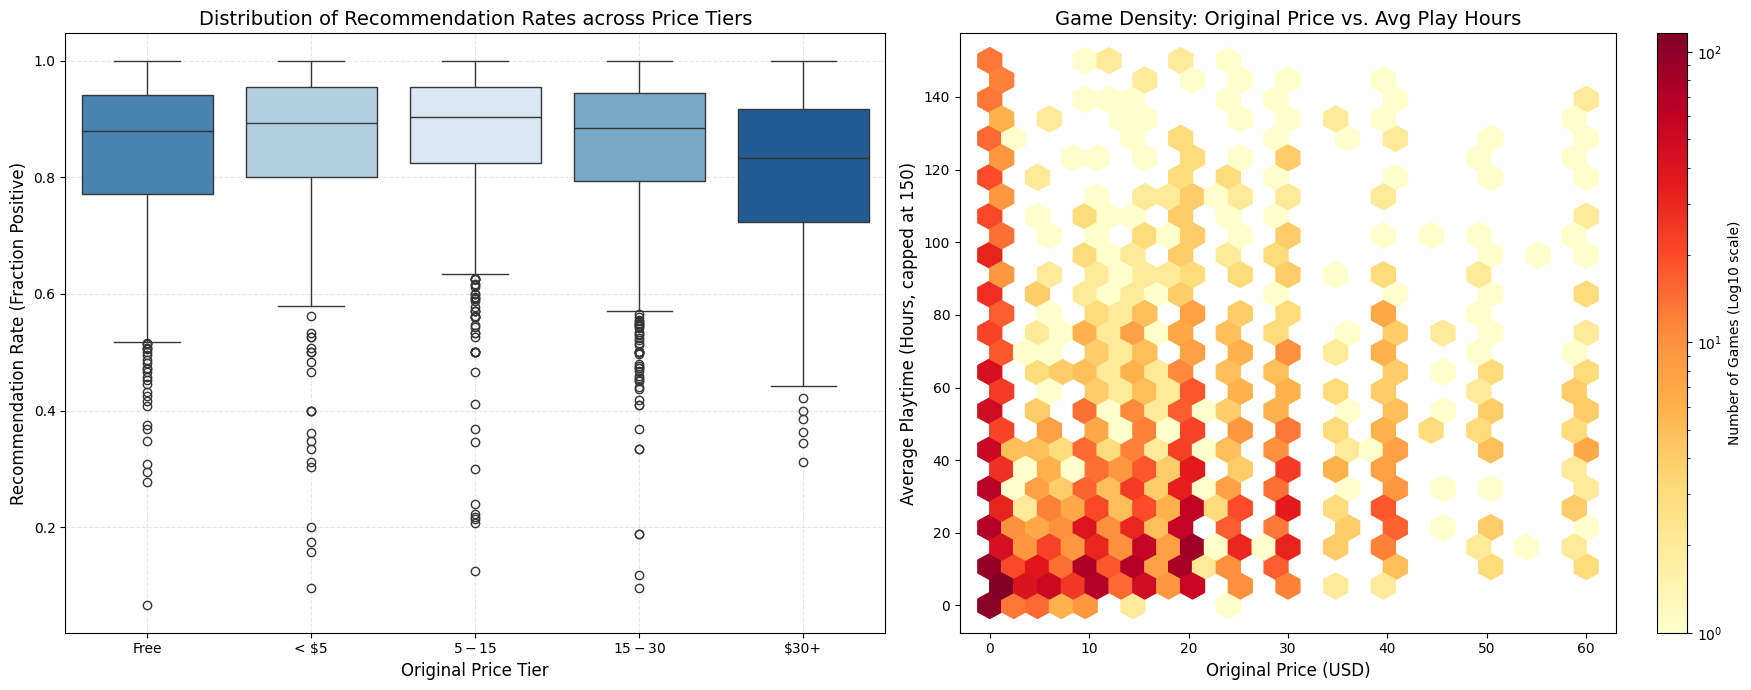

In [33]:
# Define distinct price tiers for categorical analysis
def categorize_price(price):
    if price == 0:
        return 'Free'
    elif price <= 4.99:
        return '< $5'
    elif price <= 14.99:
        return '$5 - $15'
    elif price <= 29.99:
        return '$15 - $30'
    else:
        return '$30+'

merged_df['price_tier'] = merged_df['price_original'].apply(categorize_price)
tier_order = ['Free', '< $5', '$5 - $15', '$15 - $30', '$30+']

# Filter to games with at least 15 reviews for statistically stable rates
stable_games = merged_df[merged_df['review_count'] >= 15]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Visual A
sns.boxplot(
    ax=axes[0],
    data=stable_games,
    x='price_tier',
    y='recommend_rate',
    order=tier_order,
    palette='Blues',
    hue='price_tier',
    legend=False
)
axes[0].set_title('Distribution of Recommendation Rates across Price Tiers', fontsize=14)
axes[0].set_xlabel('Original Price Tier', fontsize=12)
axes[0].set_ylabel('Recommendation Rate (Fraction Positive)', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.3)

# Visual B
hb = axes[1].hexbin(
    stable_games['price_original'],
    stable_games['avg_hours'],
    gridsize=25,
    cmap='YlOrRd',
    bins='log',
    extent=[0, 60, 0, 150] # Focus on the bulk of pricing and hours
)
fig.colorbar(hb, ax=axes[1], label='Number of Games (Log10 scale)')
axes[1].set_title('Game Density: Original Price vs. Avg Play Hours', fontsize=14)
axes[1].set_xlabel('Original Price (USD)', fontsize=12)
axes[1].set_ylabel('Average Playtime (Hours, capped at 150)', fontsize=12)

plt.tight_layout()
plt.show()

## Platform Compatibility Distribution (Windows, macOS, Linux)

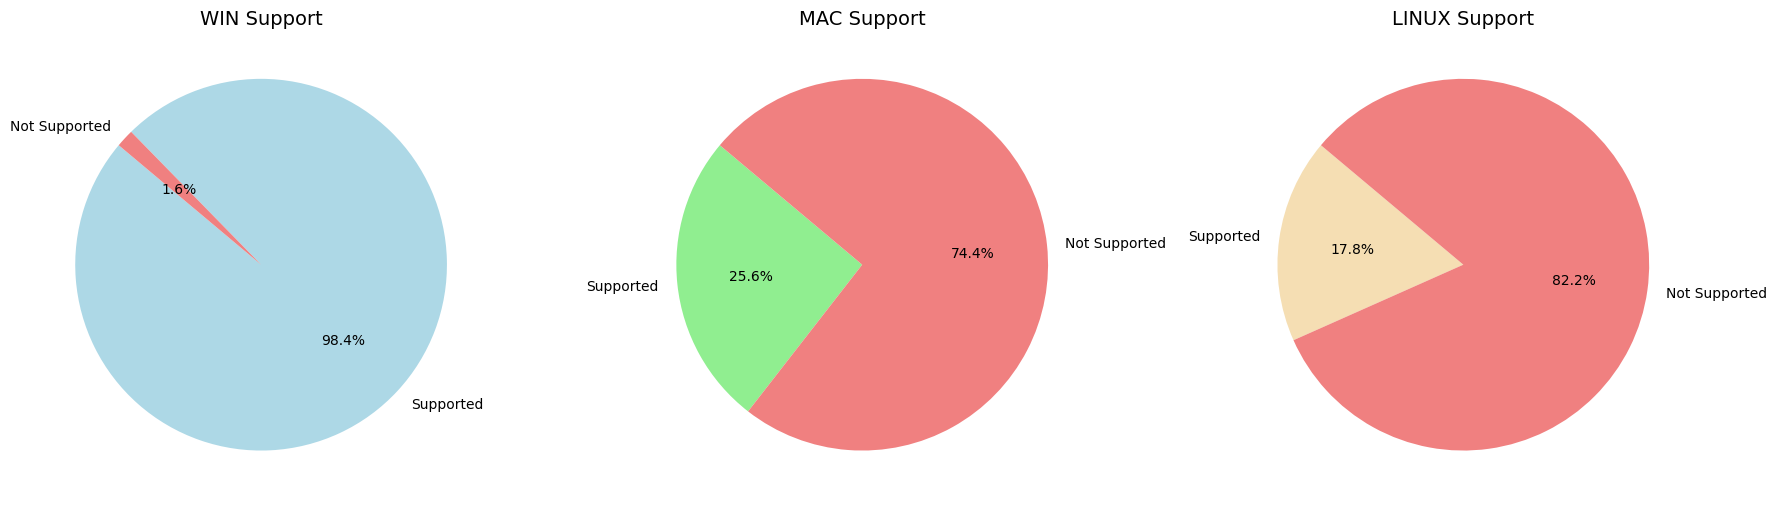

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

platforms = ['win', 'mac', 'linux']
colors = [['lightblue', 'lightcoral'], ['lightgreen', 'lightcoral'], ['wheat', 'lightcoral']]
labels = ['Supported', 'Not Supported']

for i, platform in enumerate(platforms):
    counts = games[platform].value_counts()
    sizes = [counts.get(True, 0), counts.get(False, 0)]

    axes[i].pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors[i]
    )
    axes[i].set_title(f"{platform.upper()} Support", fontsize=14)

plt.tight_layout()
plt.show()